In [1]:
# ============================================================
# ETAPE 1 : AUDIT ET SELECTION DES VARIABLES
# ============================================================

# Objectif :
# 1. Charger les données d'entraînement et de test
# 2. Examiner leur structure
# 3. Identifier les variables constantes
# 4. Analyser les valeurs manquantes
# 5. Examiner les distributions
# 6. Etudier les relations entre variables et target
# 7. Préparer une première sélection des variables

# Important :
# Aucune variable ne sera supprimée définitivement
# sans justification statistique ou expérimentale.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [3]:
DATA_DIR = Path(".")

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print("Dimensions du train :", train.shape)
print("Dimensions du test :", test.shape)

print("\nAperçu des données :")
display(train.head())

print("\nTypes des variables :")
display(train.dtypes.value_counts())

Dimensions du train : (446409, 59)
Dimensions du test : (148803, 58)

Aperçu des données :


,id,target,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,ps_ind_09_bin,ps_ind_10_bin,ps_ind_11_bin,ps_ind_12_bin,ps_ind_13_bin,ps_ind_14,ps_ind_15,ps_ind_16_bin,ps_ind_17_bin,ps_ind_18_bin,ps_reg_01,ps_reg_02,ps_reg_03,ps_car_01_cat,ps_car_02_cat,ps_car_03_cat,ps_car_04_cat,ps_car_05_cat,ps_car_06_cat,ps_car_07_cat,ps_car_08_cat,ps_car_09_cat,ps_car_10_cat,ps_car_11_cat,ps_car_11,ps_car_12,ps_car_13,ps_car_14,ps_car_15,ps_calc_01,ps_calc_02,ps_calc_03,ps_calc_04,ps_calc_05,ps_calc_06,ps_calc_07,ps_calc_08,ps_calc_09,ps_calc_10,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin
0,9,0,1,1,7,0,0,0,0,1,0,0,0,0,0,0,3,0,0,1,0.8,0.4,0.766078,11,1,-1,0,-1,11,1,1,2,1,19,3,0.316228,0.618817,0.388716,2.449490,0.3,0.1,0.3,2,1,9,5,8,1,7,3,1,1,9,0,1,1,0,1,0
1,13,0,5,4,9,1,0,0,0,1,0,0,0,0,0,0,12,1,0,0,0.0,0.0,-1.000000,7,1,-1,0,-1,14,1,1,2,1,60,1,0.316228,0.641586,0.347275,3.316625,0.5,0.7,0.1,2,2,9,1,8,2,7,4,2,7,7,0,1,1,0,1,0
2,16,0,0,1,2,0,0,1,0,0,0,0,0,0,0,0,8,1,0,0,0.9,0.2,0.580948,7,1,0,0,1,11,1,1,3,1,104,1,0.374166,0.542949,0.294958,2.000000,0.6,0.9,0.1,2,4,7,1,8,4,2,2,2,4,9,0,0,0,0,0,0
3,17,0,0,2,0,1,0,1,0,0,0,0,0,0,0,0,9,1,0,0,0.7,0.6,0.840759,11,1,-1,0,-1,14,1,1,2,1,82,3,0.316070,0.565832,0.365103,2.000000,0.4,0.6,0.0,2,2,6,3,10,2,12,3,1,1,3,0,0,0,1,1,0
4,19,0,5,1,4,0,0,0,0,0,1,0,0,0,0,0,6,1,0,0,0.9,1.8,2.332649,10,0,-1,0,0,14,1,1,0,1,104,2,0.445982,0.879049,0.406202,3.000000,0.7,0.8,0.4,3,1,8,2,11,3,8,4,2,0,9,0,1,0,1,1,1



Types des variables :


,count
int64,49
float64,10


Répartition de la variable target :


,count
target,
0,430138
1,16271



Proportions :


,proportion
target,
0,96.355136
1,3.644864


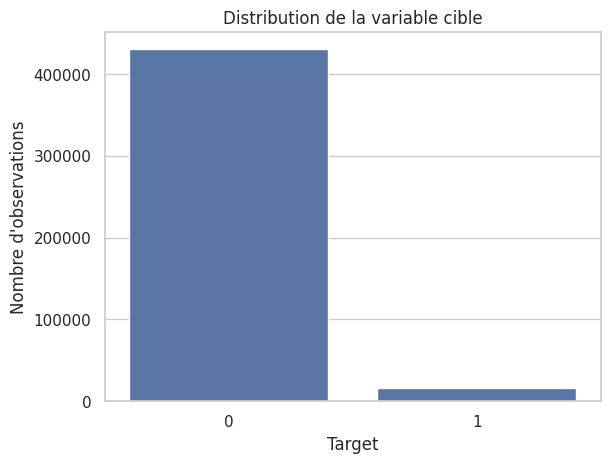

In [4]:
print("Répartition de la variable target :")
display(train["target"].value_counts())

print("\nProportions :")
display(train["target"].value_counts(normalize=True) * 100)

sns.countplot(data=train, x="target")
plt.title("Distribution de la variable cible")
plt.xlabel("Target")
plt.ylabel("Nombre d'observations")
plt.show()

In [5]:
print("Nombre d'identifiants uniques :", train["id"].nunique())
print("Nombre de lignes :", len(train))

print("\nIdentifiants dupliqués :", train["id"].duplicated().sum())
print("Lignes entièrement dupliquées :", train.duplicated().sum())

print("\nNombre de lignes avec target manquant :",
      train["target"].isna().sum())

Nombre d'identifiants uniques : 446409
Nombre de lignes : 446409

Identifiants dupliqués : 0
Lignes entièrement dupliquées : 0

Nombre de lignes avec target manquant : 0


In [6]:
features = [
    col for col in train.columns
    if col not in ["id", "target"]
]

nunique = train[features].nunique(dropna=False)

constant_variables = nunique[nunique <= 1].index.tolist()

print("Nombre de variables explicatives :", len(features))
print("Variables constantes :", constant_variables)
print("Nombre de variables constantes :", len(constant_variables))

Nombre de variables explicatives : 57
Variables constantes : []
Nombre de variables constantes : 0


In [7]:
quasi_constant_variables = []

for col in features:
    proportions = train[col].value_counts(normalize=True, dropna=False)

    if proportions.iloc[0] >= 0.99:
        quasi_constant_variables.append(col)

print("Variables quasi constantes (>= 99 % sur une valeur) :")
print(quasi_constant_variables)

Variables quasi constantes (>= 99 % sur une valeur) :
['ps_ind_10_bin', 'ps_ind_11_bin', 'ps_ind_12_bin', 'ps_ind_13_bin', 'ps_car_10_cat']


In [8]:
missing_report = pd.DataFrame({
    "variable": features,
    "missing_count": [(train[col] == -1).sum() for col in features],
    "missing_percentage": [
        (train[col] == -1).mean() * 100 for col in features
    ],
    "unique_values": [train[col].nunique() for col in features]
})

missing_report = missing_report.sort_values(
    "missing_percentage",
    ascending=False
)

display(missing_report)

,variable,missing_count,missing_percentage,unique_values
23,ps_car_03_cat,308585,69.126070,3
25,ps_car_05_cat,199982,44.797932,3
20,ps_reg_03,80977,18.139643,4979
35,ps_car_14,32107,7.192283,842
27,ps_car_07_cat,8592,1.924692,3
4,ps_ind_05_cat,4288,0.960554,8
29,ps_car_09_cat,416,0.093188,6
1,ps_ind_02_cat,167,0.037410,5
21,ps_car_01_cat,82,0.018369,13
3,ps_ind_04_cat,66,0.014785,3


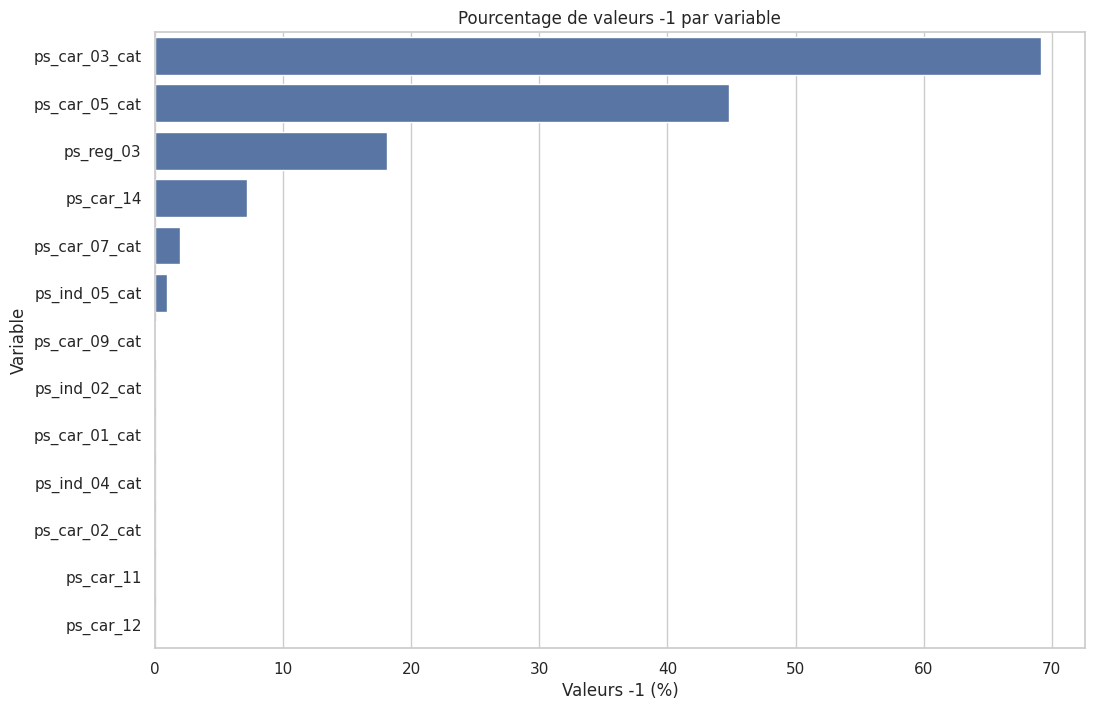

In [9]:
missing_to_plot = missing_report[
    missing_report["missing_percentage"] > 0
]

plt.figure(figsize=(12, 8))

sns.barplot(
    data=missing_to_plot,
    x="missing_percentage",
    y="variable"
)

plt.title("Pourcentage de valeurs -1 par variable")
plt.xlabel("Valeurs -1 (%)")
plt.ylabel("Variable")
plt.show()

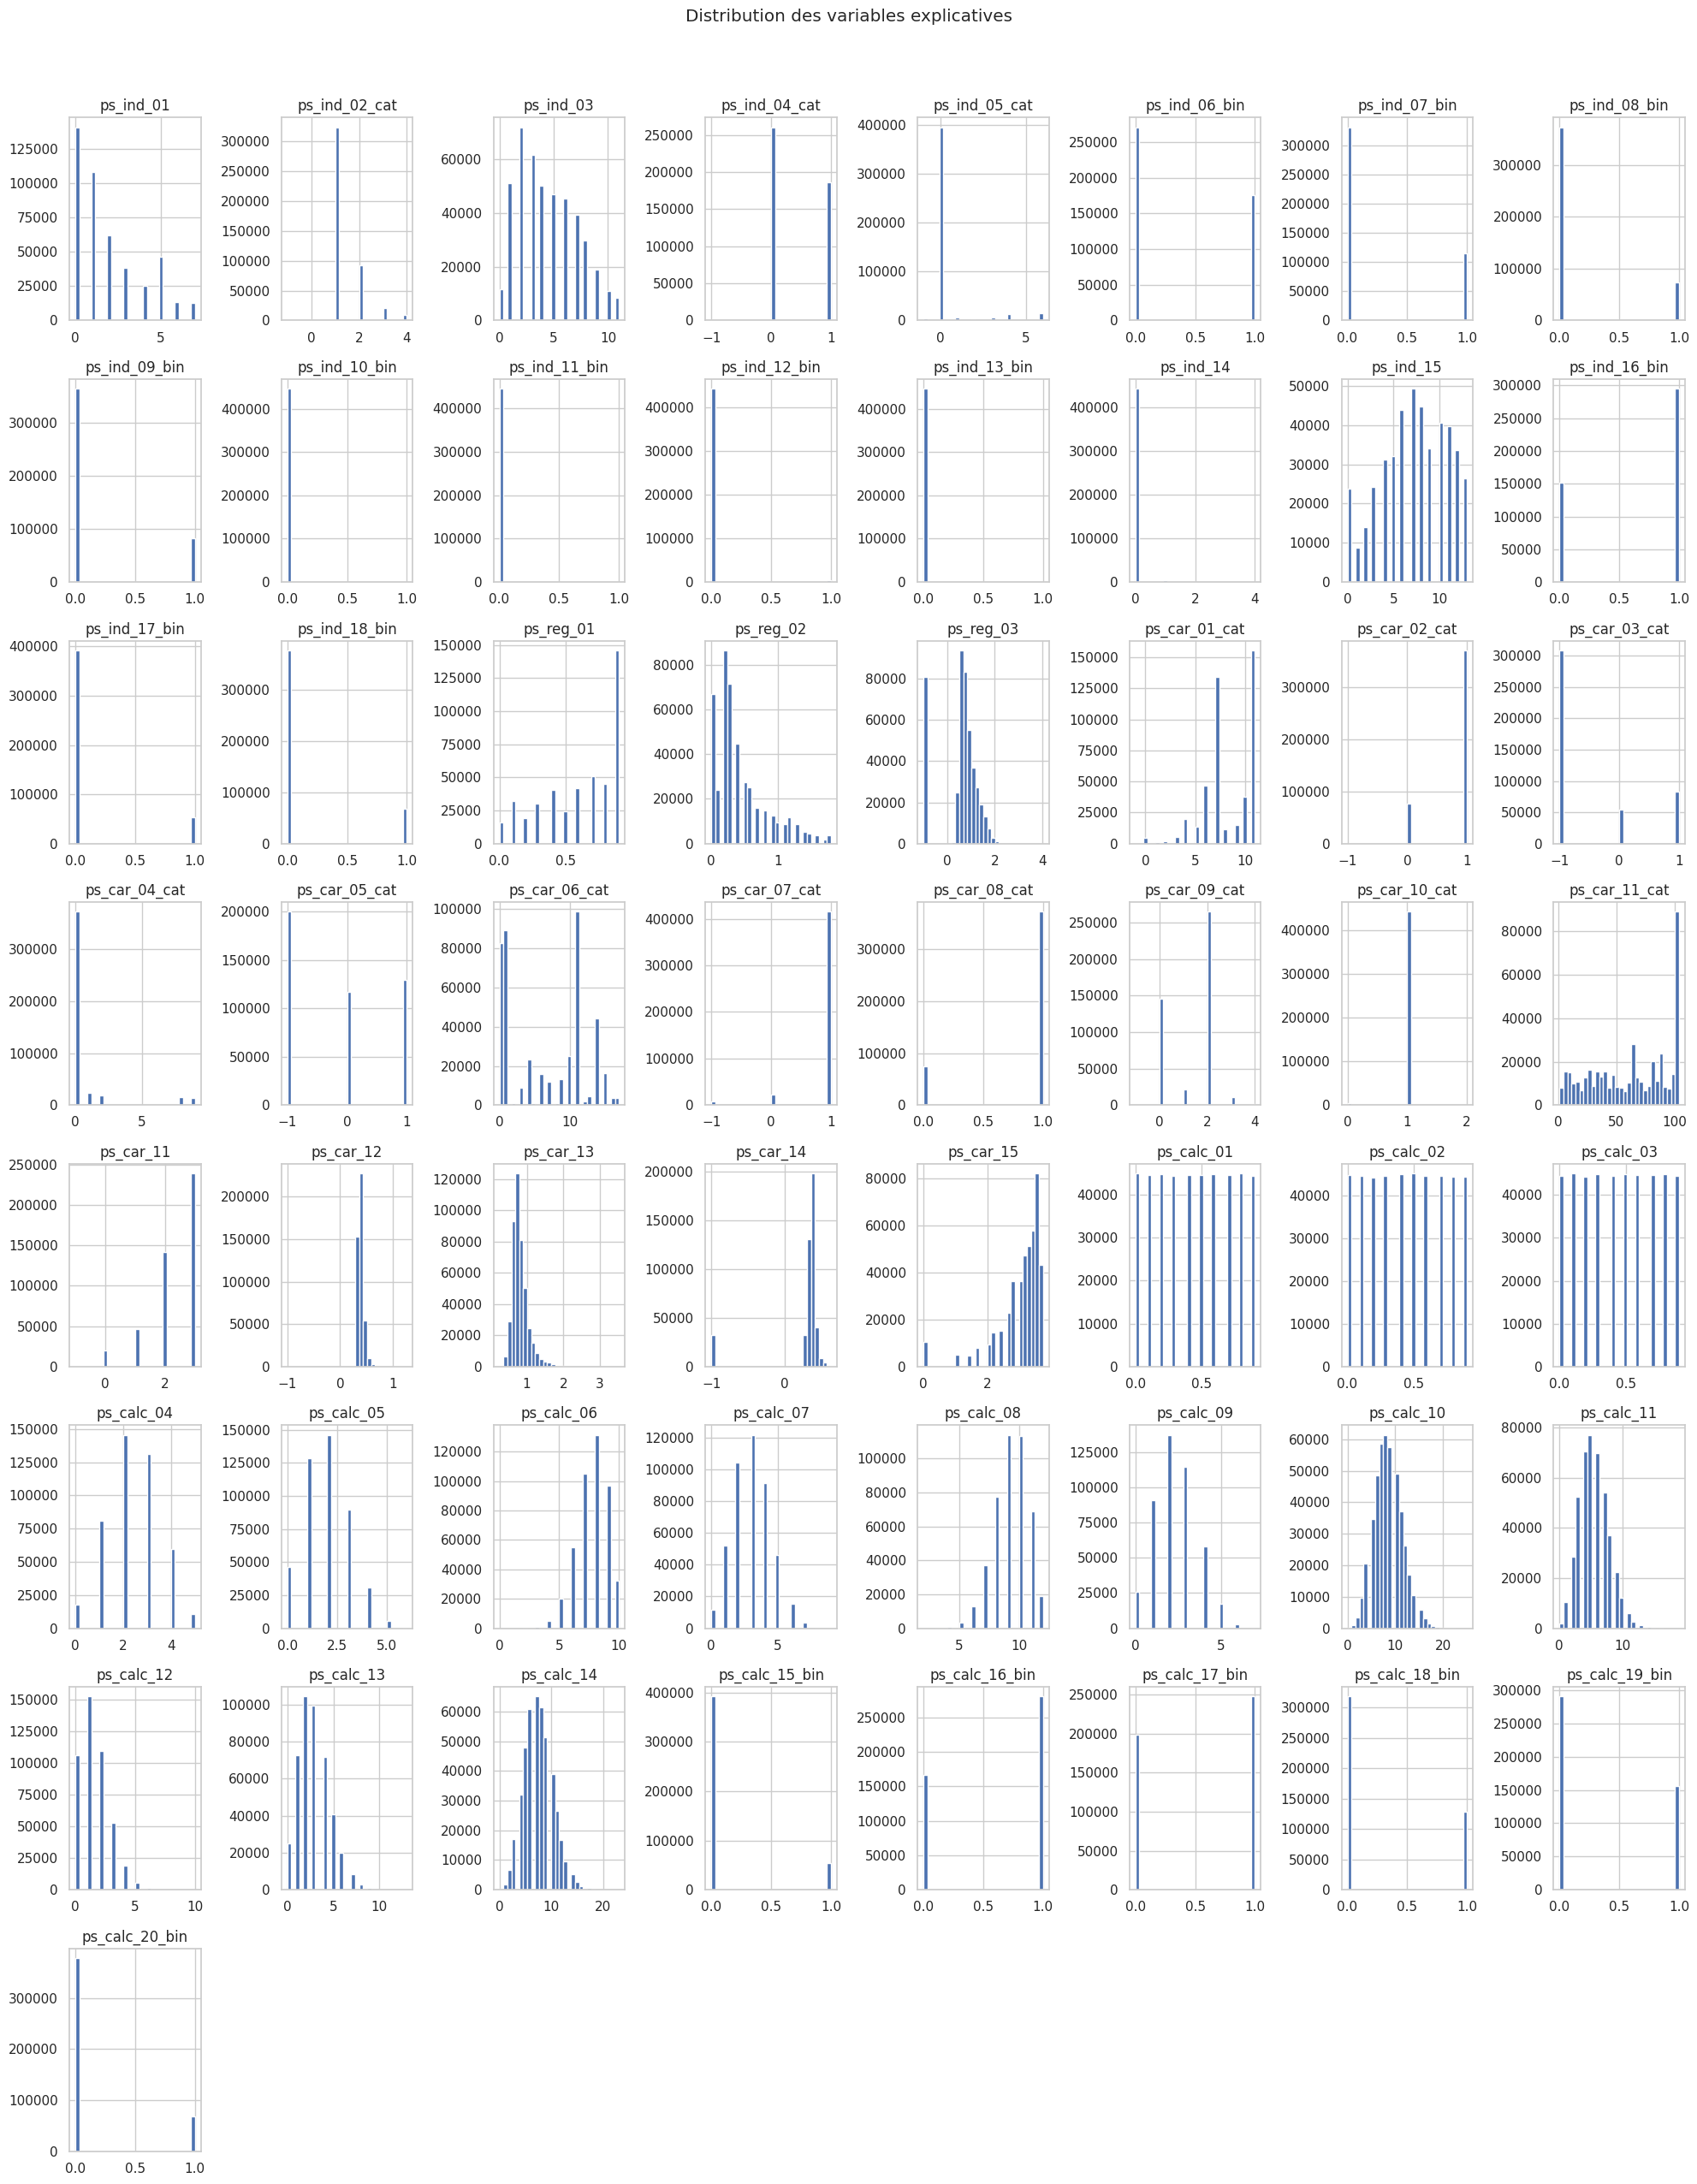

In [10]:
train[features].hist(
    figsize=(20, 25),
    bins=30
)

plt.suptitle("Distribution des variables explicatives", y=1.02)
plt.tight_layout()
plt.show()

In [11]:
variable_types = []

for col in features:
    n = train[col].nunique()

    if n <= 2:
        variable_type = "Binaire"
    elif n <= 10:
        variable_type = "Catégorielle / discrète"
    else:
        variable_type = "Continue / haute cardinalité"

    variable_types.append({
        "variable": col,
        "n_unique": n,
        "type_estime": variable_type
    })

type_report = pd.DataFrame(variable_types)

display(type_report)

,variable,n_unique,type_estime
0,ps_ind_01,8,Catégorielle / discrète
1,ps_ind_02_cat,5,Catégorielle / discrète
2,ps_ind_03,12,Continue / haute cardinalité
3,ps_ind_04_cat,3,Catégorielle / discrète
4,ps_ind_05_cat,8,Catégorielle / discrète
5,ps_ind_06_bin,2,Binaire
6,ps_ind_07_bin,2,Binaire
7,ps_ind_08_bin,2,Binaire
8,ps_ind_09_bin,2,Binaire
9,ps_ind_10_bin,2,Binaire


In [12]:
correlation_target = (
    train[features + ["target"]]
    .corr(numeric_only=True)["target"]
    .drop("target")
    .sort_values(key=abs, ascending=False)
)

display(
    correlation_target.to_frame(
        name="correlation_pearson_target"
    )
)

,correlation_pearson_target
ps_car_13,0.053688
ps_car_12,0.039300
ps_ind_17_bin,0.035790
ps_car_07_cat,-0.035518
ps_reg_02,0.034006
ps_car_04_cat,0.033640
ps_ind_06_bin,-0.033125
ps_ind_07_bin,0.032841
ps_car_02_cat,-0.032232
ps_car_03_cat,0.031173


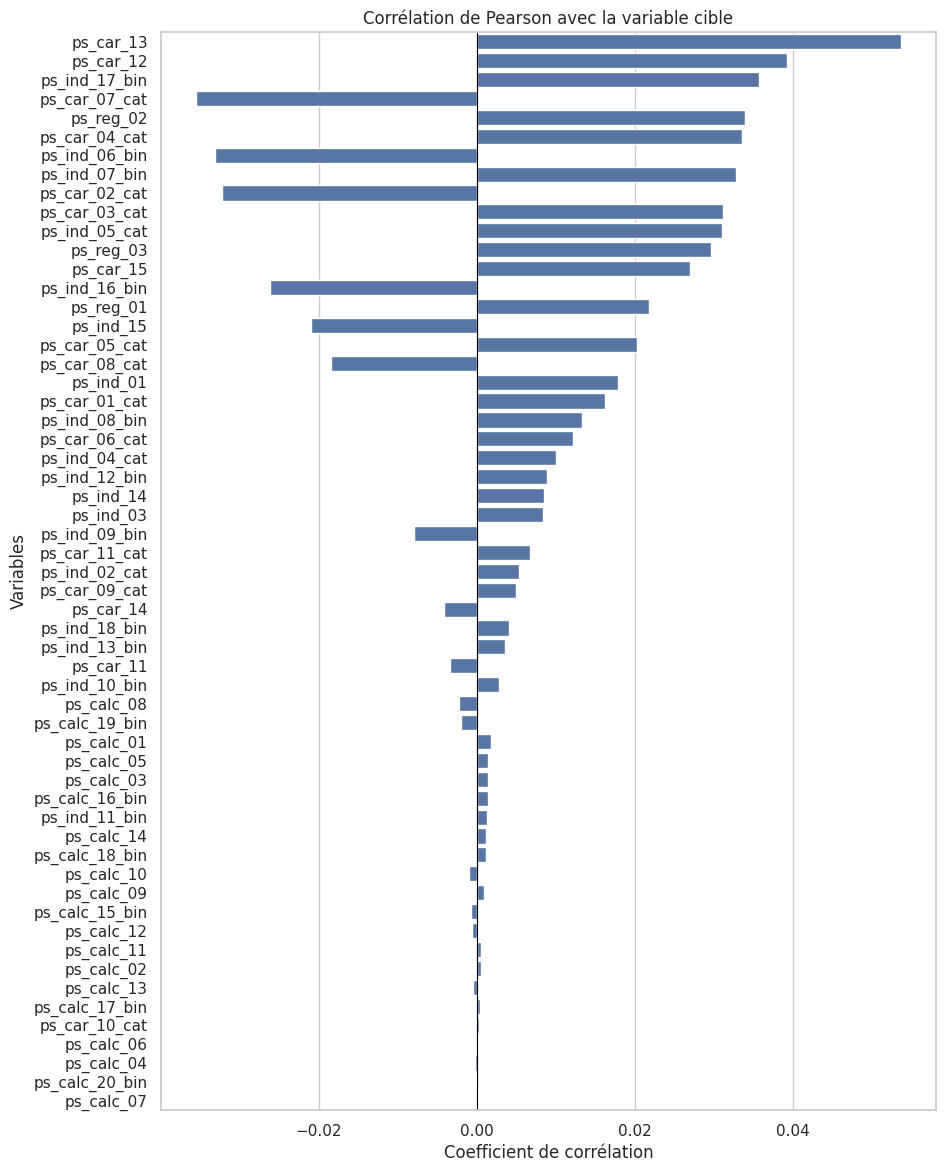

In [13]:
plt.figure(figsize=(10, 14))

sns.barplot(
    x=correlation_target.values,
    y=correlation_target.index
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Corrélation de Pearson avec la variable cible")
plt.xlabel("Coefficient de corrélation")
plt.ylabel("Variables")
plt.show()

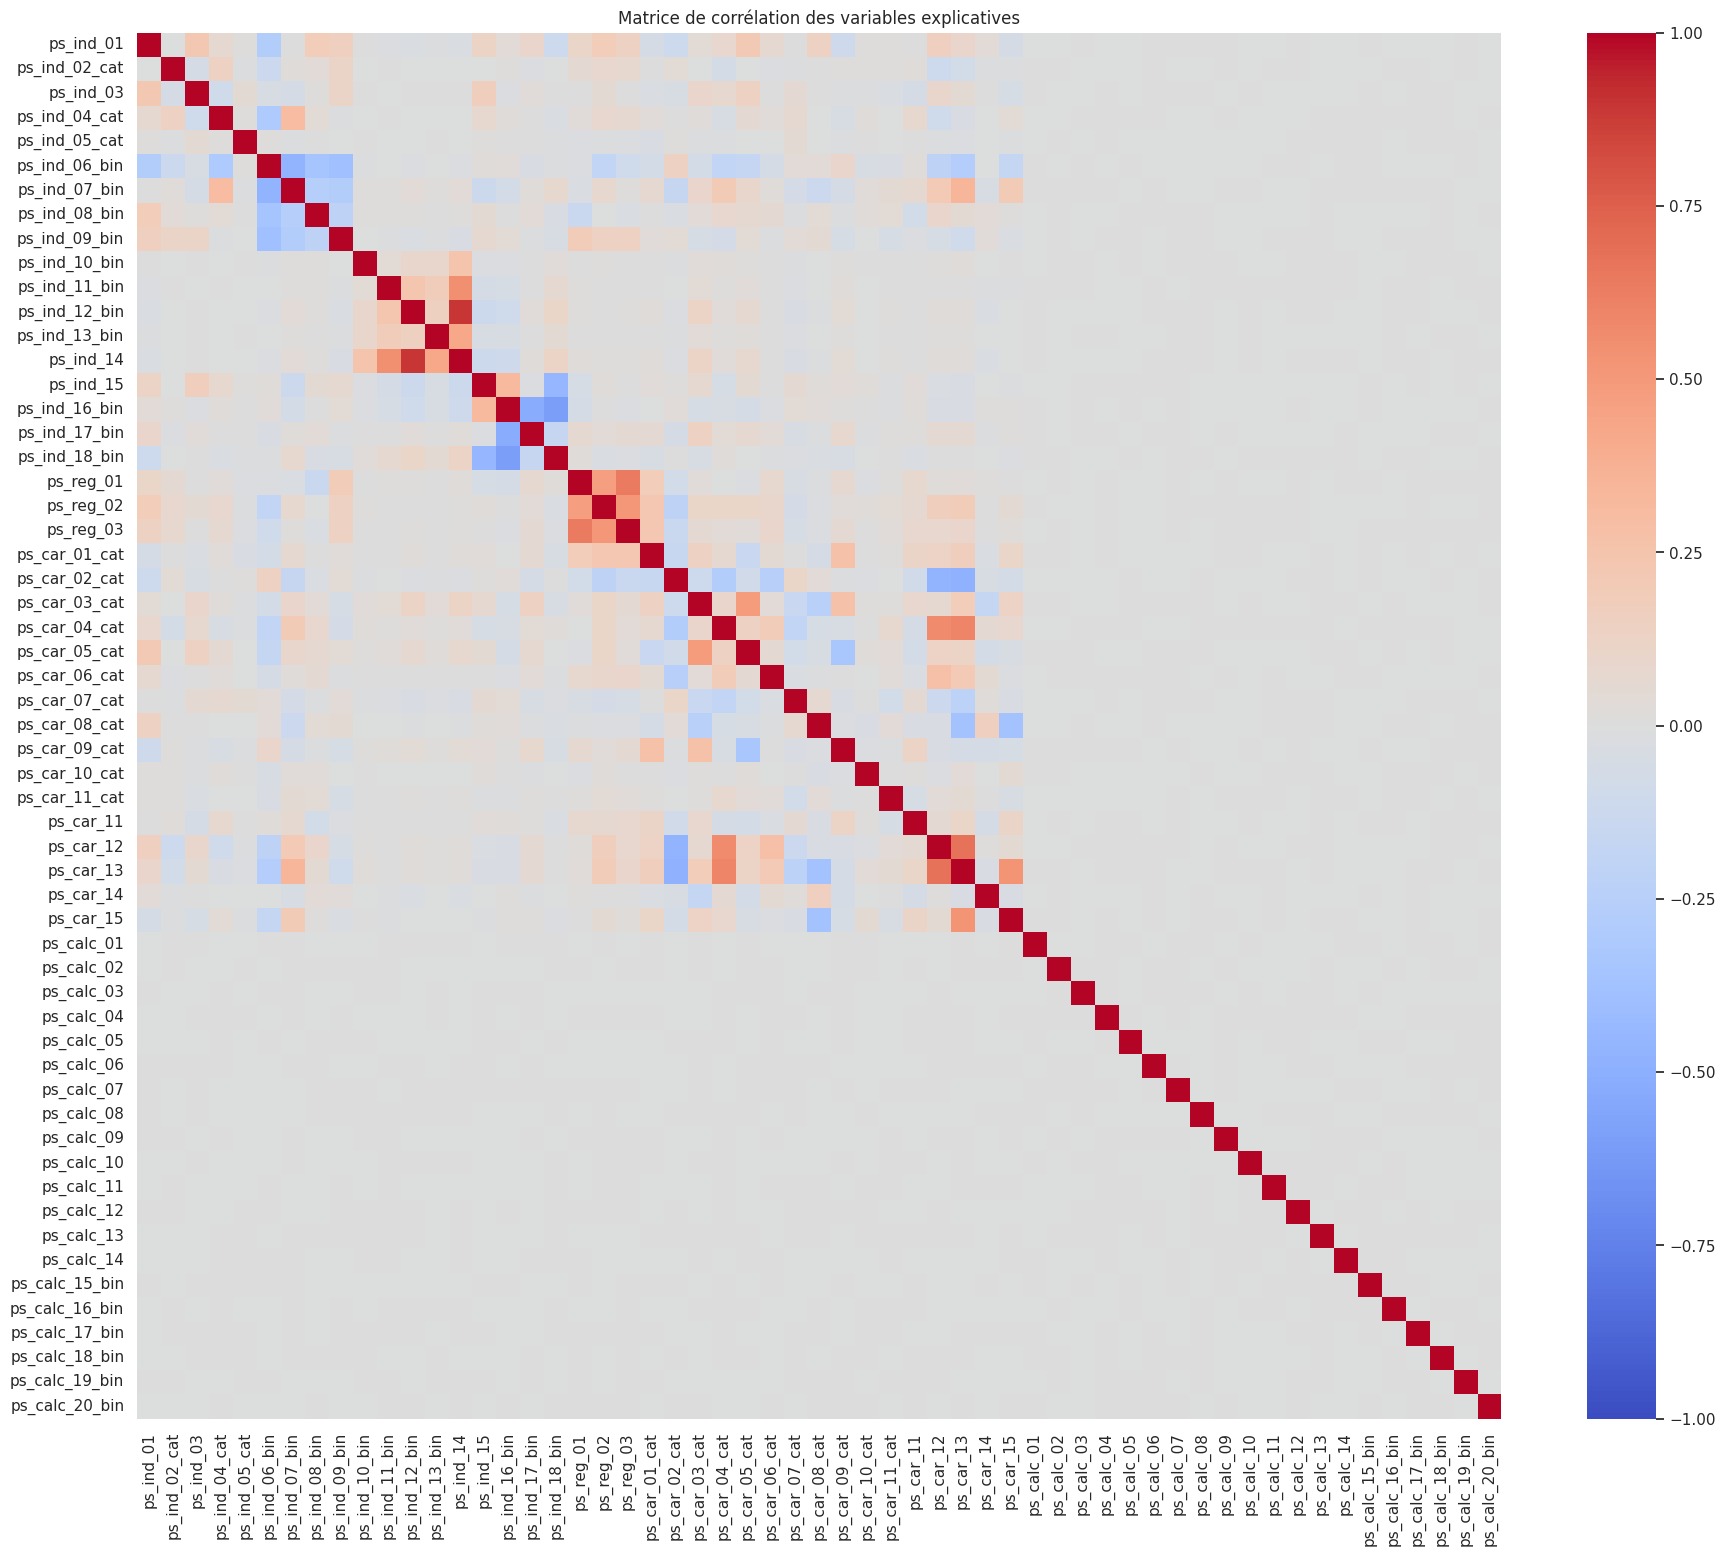

In [14]:
correlation_matrix = train[features].corr(numeric_only=True)

plt.figure(figsize=(22, 18))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Matrice de corrélation des variables explicatives")
plt.show()

In [15]:
corr_pairs = (
    correlation_matrix
    .where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

corr_pairs.columns = ["variable_1", "variable_2", "correlation"]

corr_pairs["correlation_abs"] = corr_pairs["correlation"].abs()

high_correlations = corr_pairs[
    corr_pairs["correlation_abs"] >= 0.90
].sort_values("correlation_abs", ascending=False)

display(high_correlations)

,variable_1,variable_2,correlation,correlation_abs


In [16]:
calc_features = [
    col for col in features
    if col.startswith("ps_calc_")
]

calc_report = pd.DataFrame({
    "variable": calc_features,
    "correlation_target": [
        train[col].corr(train["target"])
        for col in calc_features
    ],
    "unique_values": [
        train[col].nunique()
        for col in calc_features
    ],
    "missing_percentage": [
        (train[col] == -1).mean() * 100
        for col in calc_features
    ]
})

calc_report["correlation_abs"] = (
    calc_report["correlation_target"].abs()
)

display(
    calc_report.sort_values(
        "correlation_abs",
        ascending=False
    )
)

,variable,correlation_target,unique_values,missing_percentage,correlation_abs
7,ps_calc_08,-0.002196,11,0.0,0.002196
18,ps_calc_19_bin,-0.001933,2,0.0,0.001933
0,ps_calc_01,0.001803,10,0.0,0.001803
4,ps_calc_05,0.001468,7,0.0,0.001468
2,ps_calc_03,0.001422,10,0.0,0.001422
15,ps_calc_16_bin,0.001395,2,0.0,0.001395
13,ps_calc_14,0.001224,24,0.0,0.001224
17,ps_calc_18_bin,0.001173,2,0.0,0.001173
9,ps_calc_10,-0.000919,26,0.0,0.000919
8,ps_calc_09,0.000910,8,0.0,0.000910


In [17]:
selection_report = pd.DataFrame({
    "variable": features,
    "unique_values": [train[col].nunique(dropna=False) for col in features],
    "missing_percentage": [
        (train[col] == -1).mean() * 100 for col in features
    ],
    "correlation_target": [
        train[col].corr(train["target"]) for col in features
    ]
})

selection_report["decision_initiale"] = "A conserver provisoirement"

selection_report.loc[
    selection_report["variable"].isin(constant_variables),
    "decision_initiale"
] = "A exclure : variable constante"

selection_report.loc[
    selection_report["variable"].isin(quasi_constant_variables),
    "decision_initiale"
] = "A examiner : quasi constante"

selection_report.loc[
    selection_report["variable"].isin(calc_features),
    "decision_initiale"
] = "A tester : famille ps_calc"

selection_report.to_csv(
    "rapport_selection_initiale.csv",
    index=False
)

print("Rapport exporté : rapport_selection_initiale.csv")

display(selection_report)

Rapport exporté : rapport_selection_initiale.csv


,variable,unique_values,missing_percentage,correlation_target,decision_initiale
0,ps_ind_01,8,0.000000,0.017944,A conserver provisoirement
1,ps_ind_02_cat,5,0.037410,0.005389,A conserver provisoirement
2,ps_ind_03,12,0.000000,0.008432,A conserver provisoirement
3,ps_ind_04_cat,3,0.014785,0.010003,A conserver provisoirement
4,ps_ind_05_cat,8,0.960554,0.030993,A conserver provisoirement
5,ps_ind_06_bin,2,0.000000,-0.033125,A conserver provisoirement
6,ps_ind_07_bin,2,0.000000,0.032841,A conserver provisoirement
7,ps_ind_08_bin,2,0.000000,0.013292,A conserver provisoirement
8,ps_ind_09_bin,2,0.000000,-0.007932,A conserver provisoirement
9,ps_ind_10_bin,2,0.000000,0.002791,A examiner : quasi constante
